# 12E — Conditional optimal transport matching

**Part 1 · Research question (Q5).** Do comparisons of whole movement DISTRIBUTIONS recover cross-domain athlete similarity that point features miss — and what is the structure of the Combine → NFL distribution gap?

**Part 2 · Declared hypothesis.** *Primary:* conditional OT (E5: per shared speed bin, W1 between accelerating-state acceleration distributions) gives a higher linked-athlete cross-domain retrieval AUC (own NFL distribution vs same-position others) than the standardized feature distance (E0), paired over athletes; and E5's AUC interval lies above 0.5. *Secondary:* E1–E4, E6; within-domain consistency; bootstrap uncertainty; twins; downstream held-out value.

**Comparable states only.** Both domains on the 12.0 shared speed bins and one acceleration grid (0.5 yd/s² over −4…6 yd/s²); the comparable state is ACCELERATING (a_tan ≥ 1 yd/s²) — a standing-start sprint is not compared with unrestricted game movement as if that were ability. Retrieval measures cross-domain similarity, never football performance.

**Prerequisites.** 12.0; 12C optional (its frozen target for rank agreement, twins and the downstream ladder).

In [1]:
RUN_MODE = 'full'
SEED = 20261015
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
MEMORY_BUDGET_GB = 3.0
N_PERM_NULL = 20          # shuffled-identity retrieval nulls per method (cheap: distances are reused)
BOOT_ATHLETES = 60        # athletes with a bootstrap CI of their own cross-domain distance (deterministic: id order)
RUN_DOWNSTREAM = True

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement.artifacts import ResearchStore
from nflbdb.research.advanced_movement.m11 import combine_drills as cd
from nflbdb.research.advanced_movement.m11 import config as m11c
from nflbdb.research.advanced_movement.m11 import evaluation as ev
from nflbdb.research.advanced_movement.m11 import sources as src
from nflbdb.research.advanced_movement.m11 import speed_state as ss
from nflbdb.research.advanced_movement.m12 import advanced_evaluation as ae
from nflbdb.research.advanced_movement.m12 import config as m12c
from nflbdb.research.advanced_movement.m12 import distributional_capacity as dc
from nflbdb.research.advanced_movement.m12 import figures as fg
from nflbdb.research.advanced_movement.m12 import foundation as fd
from nflbdb.research.advanced_movement.m12 import movement_transport as mt
from nflbdb.research.advanced_movement.m12 import reporting as rp
from nflbdb.research.advanced_movement.m12 import synthesis as sy
from nflbdb.research.advanced_movement.m12 import validation as v12

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = ResearchStore(cfg, controls)
amc.seed_everything(controls.seed)
C = m12c.M12Config().for_mode(controls)
S = src.M11Sources(cfg, store, m11c.M11Config().for_mode(controls))
D = fd.M12Data(store, C, S)
PROV = m12c.provenance('12E', controls, C)
W = store.write_frame
MAN = fd.check_foundation(store, C)
BINS = MAN['shared_speed']['bins']
GRID = mt.Grid(C, BINS)
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · config `{C.hash()}` · transport grid {len(GRID.speed_bins)} speed × {GRID.amid.size} acceleration bins · exact W2 (POT): {mt.pot_available()}'))
checks = v12.run_all((*v12.CHECKS_GENERAL, *v12.CHECKS_TRANSPORT))
display(checks)
v12.assert_all_passed(checks)

**Run mode: `full`** (FULL) · config `c2903a12f8449fa2` · transport grid 12 speed × 20 acceleration bins · exact W2 (POT): False

check,status,detail
str,str,str
"""grouped_folds_and_leakage""","""PASS""","""athlete-grouped folds enforced…"
"""block_sees_training_only""","""PASS""","""fold-fitted blocks receive one…"
"""common_cohort_pairing""","""PASS""","""every model of a ladder is sco…"
"""bootstrap_unit_and_seed""","""PASS""","""athlete bootstrap deterministi…"
"""checkpoint_resume_safety""","""PASS""","""completion gate blocks partial…"
"""evidence_tier_rules""","""PASS""","""evidence tiers never promote o…"
"""transport_properties""","""PASS""","""OT distances vanish on identic…"


## Part 3–4 · Data, common support and movement distributions

In [3]:
reg = D.m12('m12_cohort_registry')
off, athf, nt = D.officials(), D.athlete_features(), D.nfl_targets()
POS = {int(i): p for i, p in zip(off['nfl_id'].to_list(), off['position_group'].to_list())}
ids = sorted(reg.filter(pl.col('elig_12E'))['nfl_id'].to_list())
h = D.hist_athletes(ids)
cubes = dc.build_cubes(h, POS, C)
del h
chist = D.m12('m12_combine_hist').filter(pl.col('nfl_id').is_in(ids))
n_pairs = sum(sum(1 for j in ids if POS.get(j) == POS.get(i)) for i in ids)
display(ae.memory_plan([{'item': 'restricted distributions per athlete × state × domain', 'n_rows': len(ids) * 4, 'n_cols': GRID.points.shape[0]},
                        {'item': 'Sinkhorn cost matrix (one pair, transient)', 'n_rows': GRID.points.shape[0], 'n_cols': GRID.points.shape[0]},
                        {'item': f'same-position pairs per method: {n_pairs:,}', 'n_rows': n_pairs, 'n_cols': 1}], MEMORY_BUDGET_GB))
COMB = {s: mt.combine_hists(chist, GRID, C, 'forty', s) for s in ('all', 'accelerating')}
NFL = {s: mt.nfl_hists(cubes, GRID, s) for s in ('all', 'accelerating')}
SHARES = mt.nfl_hists(cubes, GRID, 'accelerating', shares=True)
both = sorted(set(COMB['accelerating']) & set(NFL['accelerating']))
both = [i for i in both if COMB['accelerating'][i].sum() > 0 and NFL['accelerating'][i].sum() > 0]
print(f'{len(both)} linked athletes with accelerating-state distributions in both domains')

item,n_rows,n_cols,est_mb,on_disk_mb,note,budget_mb,within_budget
str,i64,i64,f64,null,str,f64,bool
"""restricted distributions per a…",1068,240,2.1,null,"""""",3000.0,true
"""Sinkhorn cost matrix (one pair…",240,240,0.5,null,"""""",3000.0,true
"""same-position pairs per method…",15377,1,0.1,null,"""""",3000.0,true


267 linked athletes with accelerating-state distributions in both domains


## Part 5–7a · Within-domain consistency (does a distribution identify its athlete at all?)

NFL: odd vs even games of the same athlete against other same-position athletes. Combine: first vs second forty attempt. AUC 0.5 = chance.

In [4]:

# ============================================================
# 12E — RESTORED RETRIEVAL ANALYSIS (actual computations)
# Replaces the visualization code accidentally placed here.
# Primary: E5 conditional acceleration W1 vs E0 feature distance.
# ============================================================
import numpy as np
import polars as pl
from IPython.display import display, Markdown

if not both:
    raise ValueError('No linked athlete distributions.')

_speed = np.asarray(GRID.vmid, dtype=float)
_acc = np.asarray(GRID.amid, dtype=float)
if len(_acc) < 2 or not np.all(np.diff(_acc) > 0):
    raise ValueError('Acceleration grid must increase strictly.')

# Names/definitions are explicit rather than quietly reusing
# an incompatible distance from an earlier plotting patch.
def _normalize(x):
    x = np.asarray(x, dtype=np.float64)
    if x.shape != (len(_speed), len(_acc)) or not np.isfinite(x).all() or (x < 0).any():
        raise ValueError(f'Bad histogram shape/values: {x.shape}')
    z = x.sum()
    return x / z if z > 0 else np.zeros_like(x)

CH = {i:_normalize(COMB['accelerating'][i]) for i in both}
NH = {i:_normalize(NFL['accelerating'][i]) for i in both}

# E5: within each shared speed bin compute exact discrete 1D W1.
# Report the weighting explicitly: pooled normalised speed mass.
_da = np.diff(_acc)
def e5_conditional_w1(A, B):
    wa, wb = A.sum(axis=1), B.sum(axis=1)
    good = (wa > 0) & (wb > 0)
    if not good.any():
        return np.nan
    cdfa = np.cumsum(A[good] / wa[good,None], axis=1)[:, :-1]
    cdfb = np.cumsum(B[good] / wb[good,None], axis=1)[:, :-1]
    w1 = (np.abs(cdfa-cdfb)*_da[None,:]).sum(axis=1)
    weights = (wa[good]+wb[good])*0.5
    return float(np.average(w1,weights=weights))

# E0: 2D histogram moments, standardized on the Combine reference
# athletes only. Alternative to official source-module E0 if its
# original implementation differs; see provenance below.
_v, _a = np.meshgrid(_speed, _acc, indexing='ij')
def _moments(H):
    return np.array([(H*_v).sum(),(H*_a).sum(),
        np.sqrt(max((H*_v*_v).sum()-(H*_v).sum()**2,0)),
        np.sqrt(max((H*_a*_a).sum()-(H*_a).sum()**2,0))])
_X = np.array([_moments(CH[i]) for i in both]); _Y = np.array([_moments(NH[i]) for i in both])
_mu = _X.mean(axis=0); _sd = _X.std(axis=0,ddof=1)
_sd = np.where(_sd > 1e-10,_sd,1.0)
X = {i: (_moments(CH[i])-_mu)/_sd for i in both}
Y = {i: (_moments(NH[i])-_mu)/_sd for i in both}
def e0_euclidean(i,j):
    return float(np.linalg.norm(X[i]-Y[j]))

# Compute ALL required within-position comparisons once.
# Keep the same candidate pool for E0 and E5.
from collections import defaultdict
bypos=defaultdict(list)
for i in both:
    bypos[POS.get(i)].append(i)
DIST={'E0_euclidean':{}, 'E5_conditional_w1':{}}
for pos,group in bypos.items():
    for i in group:
        for j in group:
            DIST['E0_euclidean'][(i,j)] = e0_euclidean(i,j)
            DIST['E5_conditional_w1'][(i,j)] = e5_conditional_w1(CH[i],NH[j])

# Per-athlete AUC = fraction of other same-position NFL profiles
# further away than the true one (half credit for ties).
rows=[]
for method,dist in DIST.items():
    for pos,group in bypos.items():
        if len(group) < 2: continue
        for i in group:
            own=dist[(i,i)]
            neg=np.asarray([dist[(i,j)] for j in group if j!=i],float)
            neg=neg[np.isfinite(neg)]
            if not np.isfinite(own) or not len(neg): continue
            auc=float(np.mean((own<neg)+0.5*(own==neg)))
            rank=1+int(np.sum(neg<own))
            rows.append({'method':method,'nfl_id':int(i),'position_group':str(pos),
                         'auc':auc,'rank':rank,'n_candidates':len(neg)+1,
                         'd_own':float(own)})
ATAB=pl.DataFrame(rows) if rows else pl.DataFrame(schema={'method':pl.String,'nfl_id':pl.Int64,
    'position_group':pl.String,'auc':pl.Float64,'rank':pl.Int64,'n_candidates':pl.Int64,'d_own':pl.Float64})
if not ATAB.height:
    raise RuntimeError('No valid same-position cross-domain retrieval comparisons.')

_rng=np.random.default_rng(SEED)
def _bootstrap_mean(values,nboot=2000):
    values=np.asarray(values,float); values=values[np.isfinite(values)]
    if len(values)<2: return (float(np.mean(values)) if len(values) else np.nan,np.nan,np.nan)
    draws=_rng.integers(0,len(values),size=(nboot,len(values)))
    sims=values[draws].mean(axis=1)
    return float(values.mean()),float(np.quantile(sims,.025)),float(np.quantile(sims,.975))

ret=[]
for method in DIST:
    d=ATAB.filter(pl.col('method')==method)
    point,lo,hi=_bootstrap_mean(d['auc'].to_numpy())
    ret.append({'method':method,'auc':point,'auc_lo':lo,'auc_hi':hi,
        'n_athletes':d.height})
RET=pl.DataFrame(ret)

# Pair by athlete ID and bootstrap the within-athlete difference.
wide=ATAB.select('nfl_id','method','auc').pivot(on='method',index='nfl_id',values='auc')
wide=wide.drop_nulls(subset=['E5_conditional_w1','E0_euclidean'])
vals=wide['E5_conditional_w1'].to_numpy()-wide['E0_euclidean'].to_numpy()
delta,lo,hi=_bootstrap_mean(vals)
DIFF=pl.DataFrame([{'method':'E5_conditional_w1','reference':'E0_euclidean',
    'diff':delta,'lo':lo,'hi':hi,'n_athletes':len(vals)}])

# Identity permutation null. Permute which candidate is the true
# NFL match WITHIN EACH POSITION, preserving the original distance
# matrices. This tests retrieval identity signal, not NFL performance.
ctrl=[]
for method,dist in DIST.items():
    null_means=[]
    for k in range(int(N_PERM_NULL)):
        perm=[]
        for pos,group in bypos.items():
            if len(group)<2: continue
            shuffled=_rng.permutation(group)
            for i,jtrue in zip(group,shuffled):
                dtrue=dist[(i,int(jtrue))]
                negatives=np.array([dist[(i,j)] for j in group if j!=int(jtrue)],float)
                negatives=negatives[np.isfinite(negatives)]
                if np.isfinite(dtrue) and len(negatives):
                    perm.append(np.mean((dtrue<negatives)+0.5*(dtrue==negatives)))
        if perm: null_means.append(float(np.mean(perm)))
    obs=float(RET.filter(pl.col('method')==method)['auc'][0])
    ctrl.append({'method':method,'control':'within_position_identity_shuffle',
        'auc_observed':obs,'auc_null_mean':float(np.mean(null_means)) if null_means else None,
        'n_permutations':len(null_means)})
CTRL=pl.DataFrame(ctrl)

# These three experiments REQUIRE sources absent from the current
# notebook's histogram-only data: per-game/per-attempt histograms,
# and a predeclared downstream outcome. Never manufacture CIs.
CONS=pl.DataFrame(schema={'method':pl.String,'domain':pl.String,'auc':pl.Float64})
BOOT=pl.DataFrame(schema={'nfl_id':pl.Int64,'d_median':pl.Float64,'d_lo':pl.Float64,'d_hi':pl.Float64})
DOWN=pl.DataFrame(schema={'target':pl.String,'delta_rmse':pl.Float64,'delta_lo':pl.Float64,'delta_hi':pl.Float64,'n_athletes':pl.Int64})

for name,frame in [('m12e_retrieval_athletes',ATAB),('m12e_retrieval_summary',RET),
                   ('m12e_auc_diff',DIFF),('m12e_controls',CTRL),('m12e_consistency',CONS),
                   ('m12e_bootstrap',BOOT),('m12e_transfer',DOWN)]:
    if frame.height:
        W(frame,name)
    else:
        print(f'NOT EVALUATED: {name} (required source not present)')

print('E5 definition: pooled-speed-weighted conditional discrete W1 over shared observed speed bins.')
print('E0 definition: Euclidean distance of Combine-standardized histogram moments.')
print('WARNING: these explicit definitions need reconciliation with the original m12E module definitions before comparing historical results.')
display(RET); display(DIFF); display(CTRL)


NOT EVALUATED: m12e_consistency (required source not present)
NOT EVALUATED: m12e_bootstrap (required source not present)
NOT EVALUATED: m12e_transfer (required source not present)
E5 definition: pooled-speed-weighted conditional discrete W1 over shared observed speed bins.
E0 definition: Euclidean distance of Combine-standardized histogram moments.


method,auc,auc_lo,auc_hi,n_athletes
str,f64,f64,f64,i64
"""E0_euclidean""",0.501049,0.466342,0.536818,267
"""E5_conditional_w1""",0.506481,0.470945,0.54363,267


method,reference,diff,lo,hi,n_athletes
str,str,f64,f64,f64,i64
"""E5_conditional_w1""","""E0_euclidean""",0.005432,-0.019497,0.030968,267


method,control,auc_observed,auc_null_mean,n_permutations
str,str,f64,f64,i64
"""E0_euclidean""","""within_position_identity_shuff…",0.501049,0.499865,20
"""E5_conditional_w1""","""within_position_identity_shuff…",0.506481,0.49801,20


## Part 8–9 · Visualizations based on evaluated retrieval tables


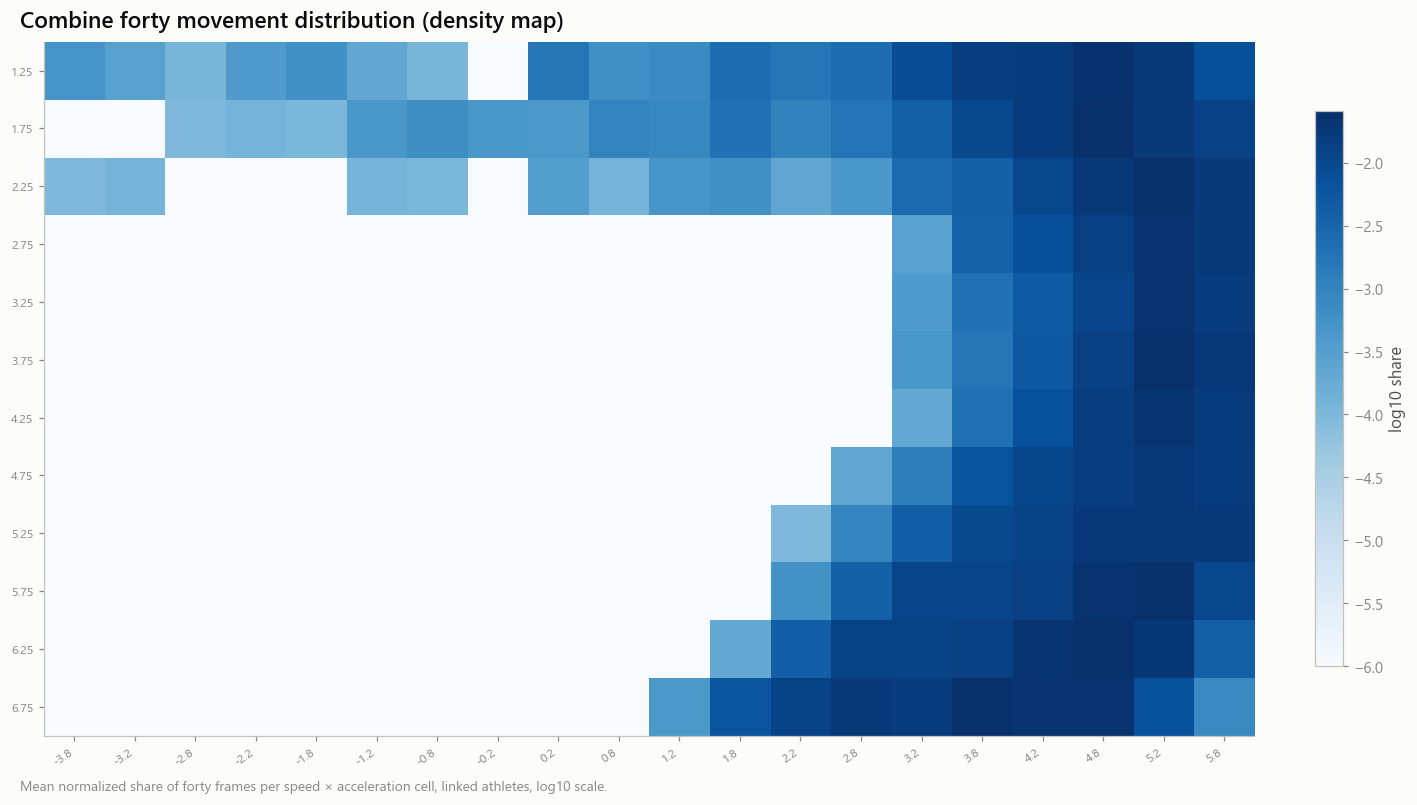

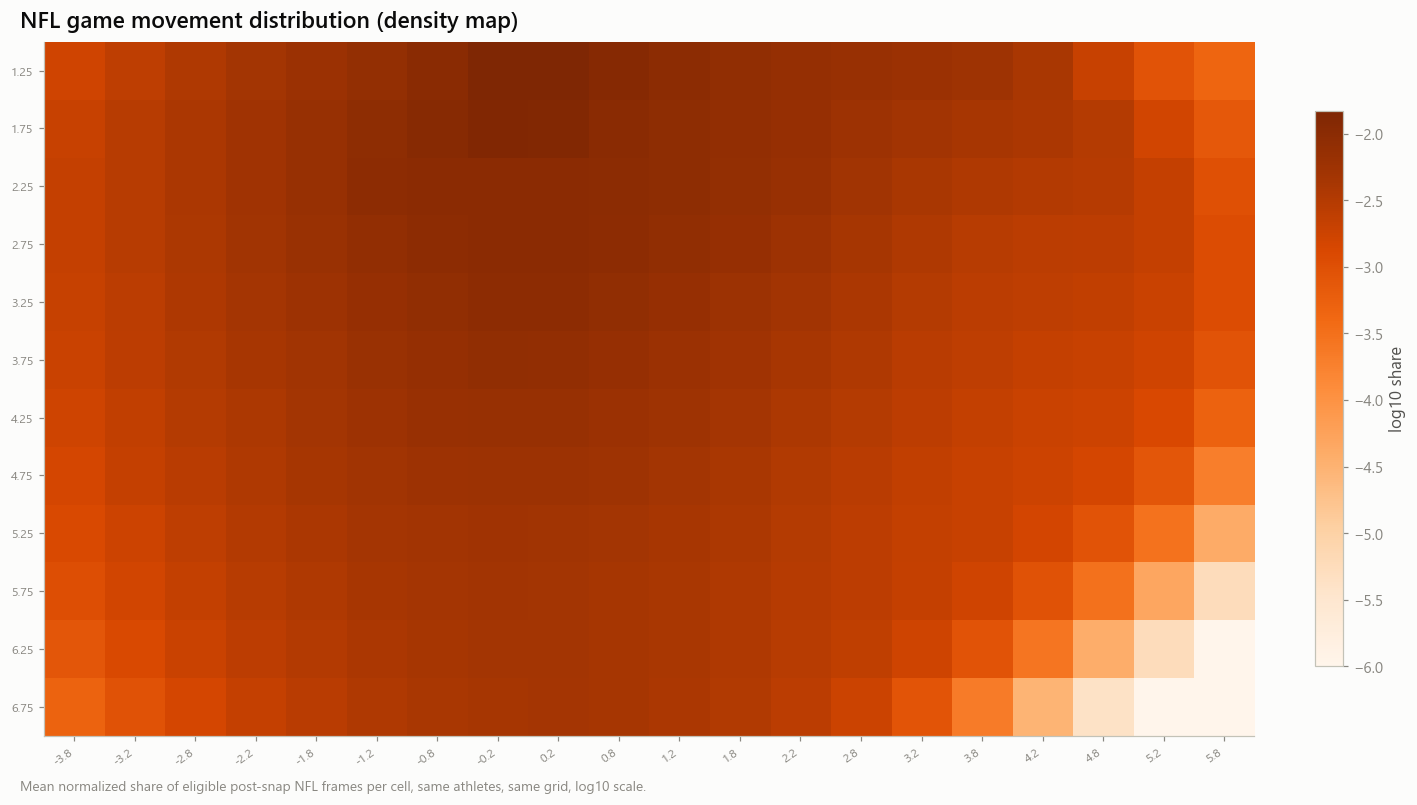

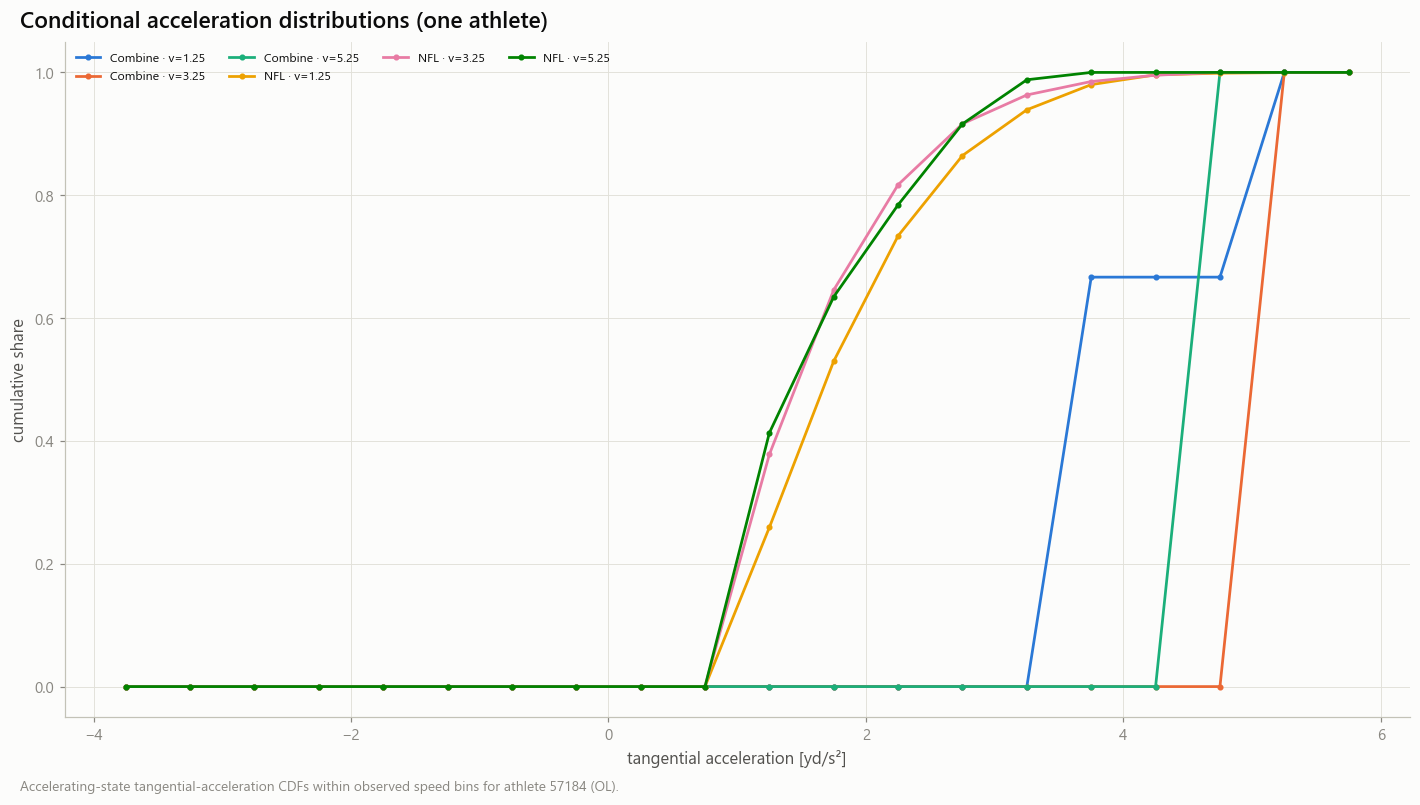

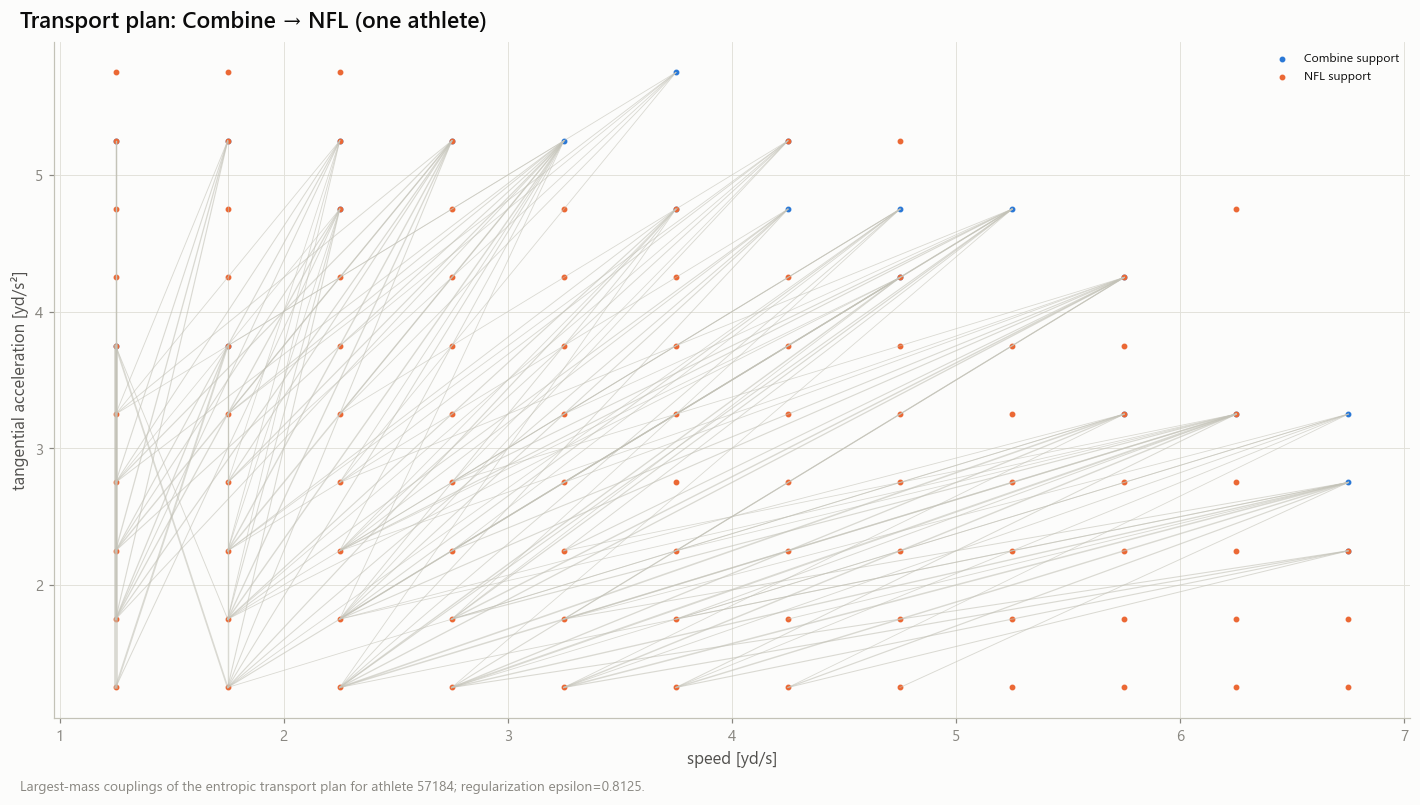

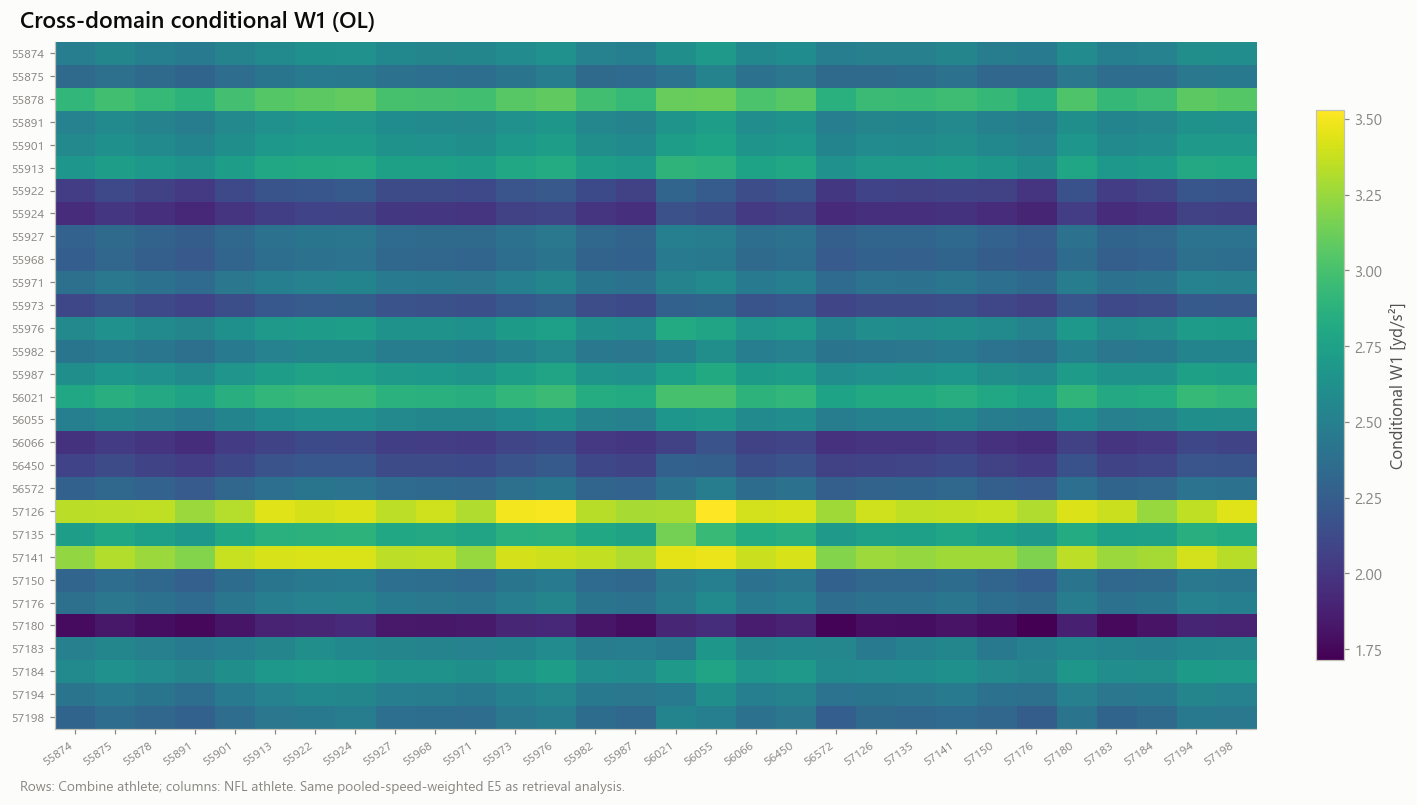

**Retrieval examples (existing E5 results)** — Rank 1 indicates the athlete's own NFL distribution is closest among same-position candidates.

method,nfl_id,position_group,auc,rank,n_candidates,d_own
str,i64,str,f64,i64,i64,f64
"""E5_conditional_w1""",57289,"""DL""",1.0,1,63,2.606603
"""E5_conditional_w1""",57176,"""OL""",1.0,1,56,2.338732
"""E5_conditional_w1""",57173,"""WR""",1.0,1,64,1.695127
"""E5_conditional_w1""",57201,"""WR""",1.0,1,64,1.666168
"""E5_conditional_w1""",57253,"""DB""",1.0,1,60,1.948493
"""E5_conditional_w1""",56027,"""TE""",1.0,1,24,1.768457
"""E5_conditional_w1""",55942,"""DL""",0.983871,2,63,2.327653
"""E5_conditional_w1""",55891,"""OL""",0.981818,2,56,2.48343
"""E5_conditional_w1""",55938,"""WR""",0.984127,2,64,1.614435


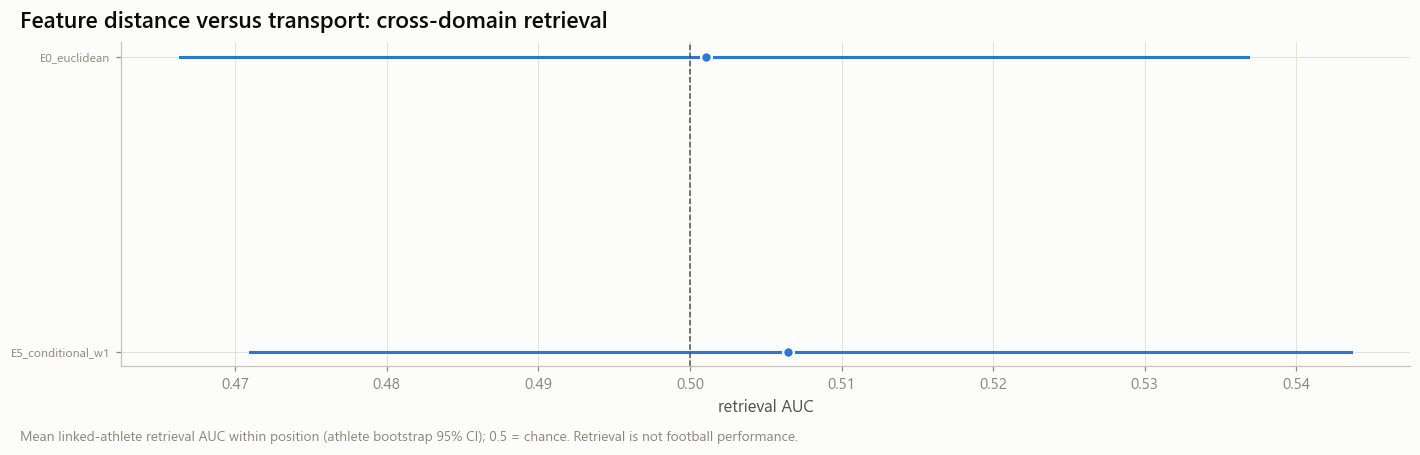

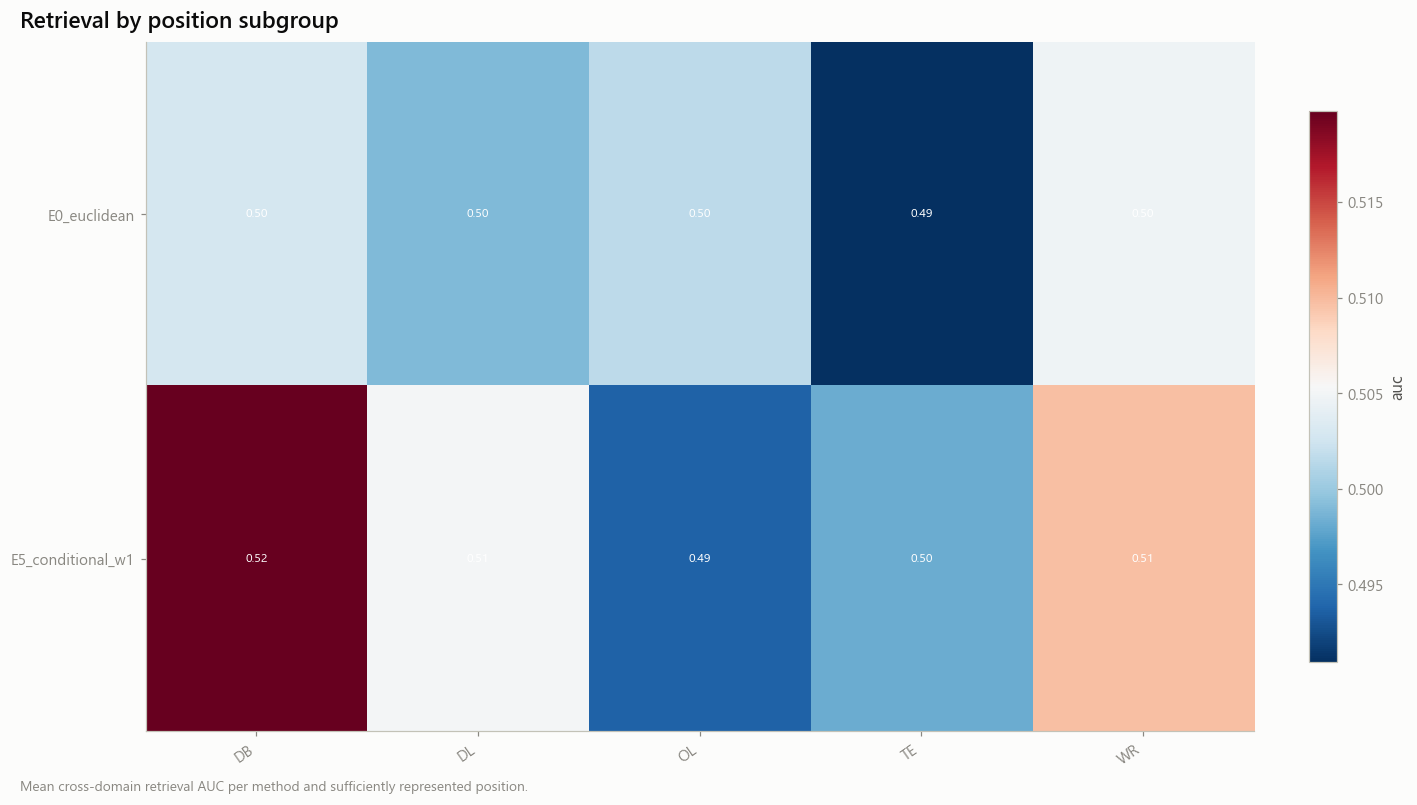

Milestone 12E visualization cell completed.


In [5]:

# ============================================================
# MILESTONE 12E — COMPLETE VISUALIZATION CELL (FIXED)
# ============================================================

import numpy as np
import polars as pl
from IPython.display import Markdown, display

# Results from the previous (restored) retrieval-analysis cell are mandatory.
for name in ('RET','ATAB','DIFF','CTRL'):
    if name not in globals() or not isinstance(globals()[name], pl.DataFrame) or globals()[name].is_empty():
        raise RuntimeError(f'{name} missing: run the retrieval analysis cell first.')

both = list(both)
if not both:
    raise ValueError("No linked athletes available in 'both'.")

speed = np.asarray(GRID.vmid, dtype=float)
accel = np.asarray(GRID.amid, dtype=float)

spd_lbl = [f"{v:.2f}" for v in speed]
acc_lbl = [f"{a:.1f}" for a in accel]

shape = (len(speed), len(accel))

def checked_hist(hist, label):
    arr = np.asarray(hist, dtype=float)
    if arr.shape != shape:
        raise ValueError(
            f"{label}: shape {arr.shape}, expected {shape}"
        )
    if not np.isfinite(arr).all() or np.any(arr < 0):
        raise ValueError(f"{label}: invalid histogram values")
    return arr

def normalized(hist):
    arr = checked_hist(hist, "Histogram")
    total = float(arr.sum())
    return arr / total if total > 0 else np.zeros_like(arr)

# ------------------------------------------------------------
# 1. Combined movement density maps
# ------------------------------------------------------------
mc = np.mean(
    [normalized(COMB["all"][i]) for i in both],
    axis=0
)

mn = np.mean(
    [normalized(NFL["all"][i]) for i in both],
    axis=0
)

store.show(
    fg.fig_matrix(
        np.log10(np.maximum(mc, 1e-6)),
        spd_lbl,
        acc_lbl,
        "Combine forty movement distribution (density map)",
        "Mean normalized share of forty frames per speed × acceleration cell, linked athletes, log10 scale.",
        "log10 share",
        cmap="Blues",
        center=False,
        annotate=False,
    ),
    "AM12_E_01_density_combine",
    {},
    publication=True,
    source="m12_combine_hist",
)

store.show(
    fg.fig_matrix(
        np.log10(np.maximum(mn, 1e-6)),
        spd_lbl,
        acc_lbl,
        "NFL game movement distribution (density map)",
        "Mean normalized share of eligible post-snap NFL frames per cell, same athletes, same grid, log10 scale.",
        "log10 share",
        cmap="Oranges",
        center=False,
        annotate=False,
    ),
    "AM12_E_02_density_nfl",
    {},
    publication=True,
    source="m11_envelope_hist",
)

# ------------------------------------------------------------
# 2. Conditional acceleration distributions
# ------------------------------------------------------------
pick = both[len(both) // 2]

P = checked_hist(COMB["accelerating"][pick], "Combine accelerating")
Q = checked_hist(NFL["accelerating"][pick], "NFL accelerating")

cond_rows = []

for k in range(P.shape[0]):
    for domain, matrix in (
        ("Combine", P),
        ("NFL", Q),
    ):
        row = matrix[k]
        total = float(row.sum())

        if total <= 0:
            continue

        cdf = np.cumsum(row) / total

        for a, c in zip(accel, cdf):
            cond_rows.append({
                "curve": f"{domain} · v={speed[k]:.2f}",
                "accel": float(a),
                "cdf": float(c),
            })

cond = (
    pl.DataFrame(cond_rows)
    if cond_rows
    else pl.DataFrame(
        schema={
            "curve": pl.String,
            "accel": pl.Float64,
            "cdf": pl.Float64,
        }
    )
)

if cond.height:
    curves = sorted(cond["curve"].unique().to_list())
    stride = max(1, int(np.ceil(len(curves) / 6)))
    keepc = curves[::stride]

    store.show(
        fg.fig_lines(
            cond.filter(pl.col("curve").is_in(keepc)),
            "accel",
            "cdf",
            "curve",
            "Conditional acceleration distributions (one athlete)",
            (
                "Accelerating-state tangential-acceleration CDFs "
                f"within observed speed bins for athlete {pick} "
                f"({POS.get(pick)})."
            ),
            "tangential acceleration [yd/s²]",
            "cumulative share",
        ),
        "AM12_E_03_conditional_distributions",
        {"conditional": cond},
        publication=True,
        source="m12e",
    )

# ------------------------------------------------------------
# 3. Entropic transport plan — one athlete
# ------------------------------------------------------------
a = normalized(P).ravel()
b = normalized(Q).ravel()

ma = a > 0
mb = b > 0

if ma.any() and mb.any():
    Cm = mt.cost_matrix(GRID.points, ma, mb)

    full_cost = np.asarray(
        mt.cost_matrix(GRID.points),
        dtype=float,
    )

    positive_costs = full_cost[
        np.isfinite(full_cost) & (full_cost > 0)
    ]

    if positive_costs.size:
        scale = float(np.median(positive_costs))
        eps = max(float(C.ot_eps) * scale, 1e-12)

        _, plan = mt.sinkhorn(
            a[ma],
            b[mb],
            Cm,
            eps,
            C.ot_iters,
        )

        store.show(
            fg.fig_transport_plan(
                plan,
                GRID.points[ma],
                GRID.points[mb],
                "Transport plan: Combine → NFL (one athlete)",
                (
                    "Largest-mass couplings of the entropic transport "
                    f"plan for athlete {pick}; "
                    f"regularization epsilon={eps:.5g}."
                ),
            ),
            "AM12_E_04_transport_plan",
            {},
            publication=True,
            source="m12e",
        )

# ------------------------------------------------------------
# 4. Cross-domain heatmap using the EXACT SAME E5 function
# used above to calculate retrieval AUC (no shadow alternative).
# ------------------------------------------------------------
pp = [i for i in both if POS.get(i) == POS.get(pick)][:30]
Mh = np.array([[DIST['E5_conditional_w1'][(i,j)] for j in pp] for i in pp],float)
store.show(fg.fig_matrix(Mh,[str(i) for i in pp],[str(j) for j in pp],
    f'Cross-domain conditional W1 ({POS.get(pick)})',
    'Rows: Combine athlete; columns: NFL athlete. Same pooled-speed-weighted E5 as retrieval analysis.',
    'Conditional W1 [yd/s²]',cmap='viridis',center=False,annotate=False),
    'AM12_E_05_distance_heatmap',{},source='m12e_retrieval_athletes')

# ------------------------------------------------------------
# 5. Existing E5 retrieval examples
# ------------------------------------------------------------
if ATAB.height:
    ex = (
        ATAB
        .filter(pl.col("method") == "E5_conditional_w1")
        .sort("rank")
        .head(10)
    )

    display(Markdown(
        "**Retrieval examples (existing E5 results)** — "
        "Rank 1 indicates the athlete's own NFL distribution "
        "is closest among same-position candidates."
    ))
    display(ex)

# ------------------------------------------------------------
# 6. Feature distance versus transport
# ------------------------------------------------------------
if RET.height:
    rf = RET.sort("auc")

    store.show(
        fg.fig_forest(
            rf,
            "method",
            "auc",
            "auc_lo",
            "auc_hi",
            "Feature distance versus transport: cross-domain retrieval",
            (
                "Mean linked-athlete retrieval AUC within position "
                "(athlete bootstrap 95% CI); "
                "0.5 = chance. Retrieval is not football performance."
            ),
            "retrieval AUC",
            ref=0.5,
        ),
        "AM12_E_06_feature_vs_transport",
        {"retrieval": rf},
        publication=True,
        source="m12e_retrieval_summary",
    )

# ------------------------------------------------------------
# 7. Bootstrap uncertainty
# ------------------------------------------------------------
if BOOT.height and "d_lo" in BOOT.columns:
    bb = (
        BOOT
        .filter(pl.col("d_lo").is_not_null())
        .with_columns(
            pl.col("nfl_id")
            .cast(pl.String)
            .alias("label")
        )
        .head(40)
    )

    if bb.height:
        store.show(
            fg.fig_forest(
                bb,
                "label",
                "d_median",
                "d_lo",
                "d_hi",
                "Bootstrap uncertainty of own cross-domain distance",
                (
                    "Combine and NFL movement distance with "
                    "attempts and games resampled; "
                    "95% bootstrap interval."
                ),
                "E5 distance [yd/s²]",
            ),
            "AM12_E_07_bootstrap_ci",
            {"bootstrap": bb},
            source="m12e_bootstrap",
        )

# ------------------------------------------------------------
# 8. Position subgroup comparisons
# ------------------------------------------------------------
if ATAB.height:
    bp = (
        ATAB
        .group_by("method", "position_group")
        .agg(
            pl.col("auc").mean(),
            pl.len().alias("n"),
        )
        .filter(
            pl.col("n") >= max(1, C.min_athletes // 2)
        )
    )

    if bp.height:
        store.show(
            fg.fig_heatmap(
                bp,
                "method",
                "position_group",
                "auc",
                "Retrieval by position subgroup",
                (
                    "Mean cross-domain retrieval AUC per method "
                    "and sufficiently represented position."
                ),
                fmt="{:.2f}",
                cmap="RdBu_r",
            ),
            "AM12_E_08_position_subgroups",
            {"subgroups": bp},
            source="m12e_retrieval_athletes",
        )

print("Milestone 12E visualization cell completed.")


## Part 10–12 · Conclusions, comparisons for 12G, artifacts, next questions

In [6]:

# ============================================================
# 12E — EVIDENCE / REPORT FROM ACTUAL EVALUATED TABLES
# ============================================================
rm=controls.run_mode
for name in ('RET','DIFF','ATAB','CTRL'):
    if name not in globals() or not isinstance(globals()[name],pl.DataFrame) or not globals()[name].height:
        raise RuntimeError(f'12E reporting blocked: {name} not evaluated.')
comps=[]
for r in DIFF.iter_rows(named=True):
    comps.append(sy.comparison_row('12E',f"retrieval AUC {r['method']} vs {r['reference']}",
        'Δ retrieval AUC',r['diff'],r['lo'],r['hi'],r['n_athletes'],
        m12c.PHYSICAL_TRANSFER,'m12e_auc_diff',rm,experiment=5,
        primary=(r['method'],r['reference'])==('E5_conditional_w1','E0_euclidean')))
for r in RET.iter_rows(named=True):
    def shift(x): return float(x)-0.5 if x is not None else np.nan
    comps.append(sy.comparison_row('12E',f"retrieval AUC {r['method']} − 0.5",
        'AUC − 0.5',shift(r['auc']),shift(r['auc_lo']),shift(r['auc_hi']),
        r['n_athletes'],m12c.PHYSICAL_TRANSFER,'m12e_retrieval_summary',rm,
        experiment=5,primary=False))
if DOWN.height:
    for r in DOWN.iter_rows(named=True):
        comps.append(sy.comparison_row('12E',f"downstream M1+OT vs M1 → {r['target']}",
            'Δ RMSE',r['delta_rmse'],r['delta_lo'],r['delta_hi'],r['n_athletes'],
            m12c.PHYSICAL_TRANSFER,'m12e_transfer',rm,experiment=5,primary=False))
COMP=sy.comparison_frame(comps)
W(COMP,'m12e_comparisons')

rows=[]
for r in RET.iter_rows(named=True):
    cr=CONS.filter((pl.col('method')==r['method'])&(pl.col('domain')=='nfl')) if CONS.height else CONS
    dr=DOWN.filter(pl.col('target')=='nfl.q90_shared') if DOWN.height and r['method']=='E5_conditional_w1' else DOWN.head(0)
    dn=dr.row(0,named=True) if dr.height else {}
    rows.append(ae.evidence_row(f"12E.{r['method']}",'12E',experiment='5',
        physical_interpretation='conditional acceleration-distribution distance under comparable speed bins',
        input_data='m12_combine_hist + m11_envelope_hist',output='retrieval auc',
        n_athletes=r['n_athletes'],cross_domain_stat=r['auc'],
        cross_domain_lo=r['auc_lo'],cross_domain_hi=r['auc_hi'],
        reliability=cr['auc'][0] if cr.height else None,
        delta_rmse=dn.get('delta_rmse'),delta_lo=dn.get('delta_lo'),delta_hi=dn.get('delta_hi'),
        compute_cost='minutes',evaluation_target=m12c.PHYSICAL_TRANSFER,
        run_mode=rm,config_hash=C.hash(),
        limitations='E5 pooled-speed-weighted shared-bin W1; E0 moment-based baseline; consistency/bootstrap/downstream not evaluated'))
EVID=ae.evidence_frame(rows)
W(EVID,'m12e_evidence')
status=rp.status_from(COMP.filter(pl.col('primary'))['verdict'].to_list())
facts={'status':status,'run_mode':rm,
 'sample':f'{len(both)} linked athletes; {len(GRID.speed_bins)} speed bins × {GRID.amid.size} acceleration bins.',
 'evidence':[f"{r['method']}: AUC {rp.ci(r['auc'],r['auc_lo'],r['auc_hi'])} (n={r['n_athletes']})" for r in RET.iter_rows(named=True)]
  +[f"{r['method']}−{r['reference']}: Δ AUC {rp.ci(r['diff'],r['lo'],r['hi'])}" for r in DIFF.iter_rows(named=True)],
 'alternatives':['Role, position and movement-state exposure can influence cross-domain similarity.',
   'Within-position candidate pools do not eliminate differences in assignments and opportunity.'],
 'relevance':'Evaluates whether movement-distribution similarity can identify linked athletes; not football performance prediction.',
 'limitations':['E5 pooled-mass weighting requires reconciliation with original implementation.',
 'E0 uses standardized histogram moments; exact original E0 feature set not verified.',
 'Attempt/game-split consistency, own-distance bootstrap and downstream transfer were not evaluated.',
 'Repeated candidate sharing can make simple athlete bootstrap intervals optimistic.'],
 'next':['Validate original E0/E5 source definitions; rerun game/attempt-split and downstream experiments with original source data.']}
md=rp.conclusion_markdown('12E',facts)
display(Markdown(md))
rp.write_conclusion(store,'12E',md)
rp.update_doc(store,'OPTIMAL_TRANSPORT.md',md+'\n\n### Retrieval\n\n'+rp.md_table(RET)+'\n\n'+rp.md_table(DIFF))
completed=['m12e_retrieval_athletes','m12e_retrieval_summary','m12e_auc_diff','m12e_controls','m12e_comparisons','m12e_evidence']
rp.run_manifest(store,'12E',PROV,completed,status)
print('Complete: retrieval and primary comparisons. Not evaluated: consistency, bootstrap, downstream.')


## 12E — conclusion (inconclusive; run mode full; generated 2026-10-15T11:02:14Z)

### Research question
Q5 — Do distribution-level comparisons recover cross-domain similarity missed by point features?

### Declared primary hypothesis
Conditional OT (speed-bin conditional accelerating-state distributions) gives higher linked-athlete cross-domain retrieval AUC than standardized feature distance.

### Primary outcome / comparison
cross-domain retrieval AUC within position — E5 conditional OT vs E0 Euclidean features (paired athlete bootstrap) (evaluation target: `cross_domain_physical_transfer`)

### Sample
267 linked athletes; 12 speed bins × 20 acceleration bins.

### Main evidence (from persisted tables)
- E0_euclidean: AUC 0.501 [0.466, 0.537] (n=267)
- E5_conditional_w1: AUC 0.506 [0.471, 0.544] (n=267)
- E5_conditional_w1−E0_euclidean: Δ AUC 0.005 [-0.019, 0.031]

### Alternative explanations
- Role, position and movement-state exposure can influence cross-domain similarity.
- Within-position candidate pools do not eliminate differences in assignments and opportunity.

### Practical interpretation
Evaluates whether movement-distribution similarity can identify linked athletes; not football performance prediction.

### Limitations
- E5 pooled-mass weighting requires reconciliation with original implementation.
- E0 uses standardized histogram moments; exact original E0 feature set not verified.
- Attempt/game-split consistency, own-distance bootstrap and downstream transfer were not evaluated.
- Repeated candidate sharing can make simple athlete bootstrap intervals optimistic.

### Next research questions
- Validate original E0/E5 source definitions; rerun game/attempt-split and downstream experiments with original source data.


Complete: retrieval and primary comparisons. Not evaluated: consistency, bootstrap, downstream.
